In [1]:
import pandas as pd
import pyecap
import os
from pathlib import Path
import scipy.io as sio
import numpy as np
import pyecap.io.adinstruments_io
import ast
import matplotlib.pyplot as plt
import sys
from plotly_resampler import register_plotly_resampler, unregister_plotly_resampler
from pyecap.io.adinstruments_io import AdInstrumentsIO, convert_time, ADInstrumentsBin
import datetime
import plotly.graph_objects as go
import plotly.io as pio
#from plotly_resampler import FigureResampler, FigureWidgetResampler
from scipy import signal, fft
from scipy.optimize import curve_fit
import seaborn as sns

In [2]:
""" Sigmoid Function Definitions """
def sigmoid(x, y_max, slope, inf_pt, y_min):
    return y_max / (1 + np.exp(-slope * (x - inf_pt))) + y_min

def sigmoid_log10(x, y_max, slope, inf_pt, y_min):
    return y_max / (1 + 10**(-slope * (x - inf_pt))) + y_min

# def sigmoid_fit(dataDF, y_variable, init_params = [1,1,100,0], bounds = ([0, 0, 0, -np.inf], [np.inf, np.inf, np.inf, np.inf]), log_transform = False, pad_min=False):
#     y_max, slope, inf_pt, y_min = init_params

#     x_d = np.array(dataDF['pulse amplitude (μA)'])
#     y_d = np.array(dataDF[y_variable])
#     y_max = np.max(y_d)
#     #y_max = np.median(dataDF.loc[ dataDF['pulse amplitude (μA)'] >= 2000, y_variable])

#     if pad_min:
#         x_d = np.insert(x_d, 0,10)
#         y_d = np.insert(y_d, 0,0)

#     if log_transform:
#         x_d = np.log10(x_d)
#         inf_pt = np.log10(inf_pt)
#         popt,pcov = curve_fit(sigmoid_log10, xdata = x_d, ydata = y_d, p0 = [y_max, slope, inf_pt, y_min], bounds = bounds, max_nfev=10000)
#     else:
#         popt,pcov = curve_fit(sigmoid, xdata = x_d, ydata = y_d, p0 = [y_max, slope, inf_pt, y_min], bounds = bounds, max_nfev=10000)

#     # print(x_d)
#     # print(y_max)

#     return popt,pcov

def sigmoid_fit(x, y, init_params = [1,1,100,0], bounds = ([0, 0, 0, -np.inf], [np.inf, np.inf, np.inf, np.inf]), log_transform = False, pad_min=False):
    y_max, slope, inf_pt, y_min = init_params

    #x_d = np.array(dataDF['pulse amplitude (μA)'])
    #y_d = np.array(dataDF[y_variable])
    x_d = x
    y_d = y
    y_max = np.max(y_d)
    #y_max = np.median(dataDF.loc[ dataDF['pulse amplitude (μA)'] >= 2000, y_variable])

    if pad_min:
        x_d = np.insert(x_d, 0,10)
        y_d = np.insert(y_d, 0,0)

    if log_transform:
        x_d = np.log10(x_d)
        inf_pt = np.log10(inf_pt)
        popt,pcov = curve_fit(sigmoid_log10, xdata = x_d, ydata = y_d, p0 = [y_max, slope, inf_pt, y_min], bounds = bounds, max_nfev=10000)
    else:
        popt,pcov = curve_fit(sigmoid, xdata = x_d, ydata = y_d, p0 = [y_max, slope, inf_pt, y_min], bounds = bounds, max_nfev=10000)

    # print(x_d)
    # print(y_max)

    return popt,pcov

In [23]:
#filePATH = r'G:\Data\EN_Mapping\LM6_190529\pnpig_190529-190529-123411'
filePATH = r'G:\Data\EN_Mapping\LM6_190529\pnpig_190529-190529-125219'
#filePATH = r'G:\Data\EN_Mapping\LM6_190529\pnpig_190529-190529-124227'

"""Import Stimulation data"""
stim_data = pyecap.Stim(filePATH)
stimDF = stim_data.parameters

"""Instantiate pyecap objects"""
emg_drop_ch = ['Wav1 ' + str(ch) for ch in [1,2,3,4,11,12,13,14,15,16]]

raw_ephys = pyecap.Ephys(filePATH, stores = 'Wav1')
raw_emg = raw_ephys.remove_ch(emg_drop_ch)
raw_emg = raw_emg.channel_reference(channel = 'Wav1 7')

# Filtering
raw_emg_f = raw_emg.filter_gaussian(Wn = 3000, btype='lowpass')
#raw_emg_f = raw_emg_f.filter_powerline()
raw_emg_f = raw_emg_f.filter_median(btype='highpass')

EMGf = pyecap.EMG(raw_emg_f, stim_data)

In [24]:
raw_data = raw_ephys.array[raw_ephys._ch_to_index('Wav1 8')].compute()

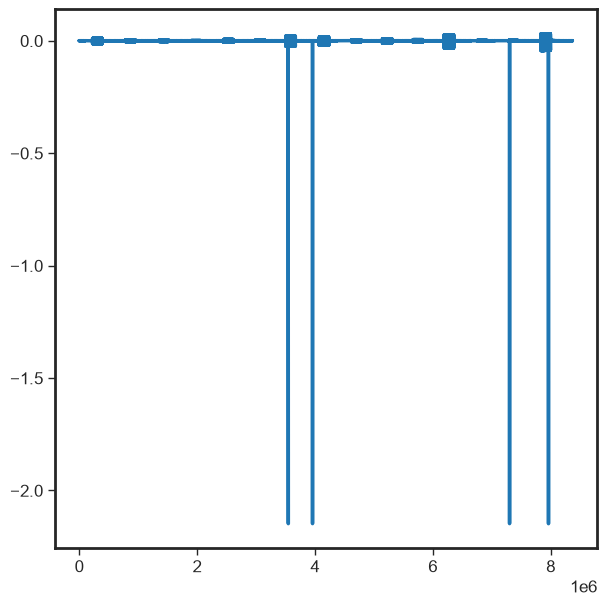

In [25]:
fig,ax = plt.subplots(figsize = (7,7))
ax.plot(np.squeeze(raw_data))
plt.show()

In [26]:
register_plotly_resampler(mode = 'auto', default_n_shown_samples = 5000)
fig = go.Figure()
fig.update_layout(spikedistance = 0)

fig.add_trace(go.Scattergl(x = raw_ephys.time(), y = raw_data[0,:]))
#fig.add_trace(go.Scattergl(x = raw_emg.time(), y = emg_d[0,:]))
fig.show()

FigureWidgetResampler({
    'data': [{'name': '<b style="color:sandybrown">[R]</b> trace 0 <i style="color:#fc9944">~0.07</i>',
              'type': 'scattergl',
              'uid': 'ace95efd-92c9-4e13-9fc0-75b213dc4e59',
              'x': {'bdata': ('AAAAAAAAAAAjIog1jdSYP5LvraMFw7' ... 'JkanVAvXUXi1NrdUAeEPC9Imx1QA=='),
                    'dtype': 'f8'},
              'y': {'bdata': ('PI9iNy9kZ7hIZ6I4C91JuKWGjDhiuo' ... 'S4ECEXOPKGU7gfmaE3lg98uDJbJbc='),
                    'dtype': 'f4'}}],
    'layout': {'spikedistance': 0, 'template': '...'}
})

In [ ]:
""" In rms, dim 1 = pulse #, dim 2 = channel 
For curve fitting:
X data = pulse amplitude
Y data = RMS based on calculation
"""

rms = EMGf.pulse_RMS(parameters = stimDF.index.tolist(), channels = 'Wav1 8', window = (6,10), window_units = 'ms')
rms_max = np.max([np.max(rms[param]) for param in rms.keys()])

# Need to find a way to identify outlier pulses (e.g. those that had the preamp rail and exclude them from the analysis)

# Construct long format data array where one dim is pulse amplitude and the other is the Y values
data = []
for param in rms.keys():
    amp = np.abs(stimDF.loc[param, 'pulse amplitude A (μA)'])
    amp_array = np.ones((rms[param].shape[0],1)) * amp

    data.append( np.hstack([amp_array, rms[param]]))
    #data.append( np.hstack([amp_array, rms[param]/rms_max]))

    #print(amp)
data = np.vstack(data)
popt, pcov = sigmoid_fit(x = data[:,0], y = data[:,1], init_params = [1,1,150,0], log_transform = True, pad_min = True)

--- Fit Results ---
Bottom:     0.05 ± 24.96
Top:        0.33 ± 3.79
LogEC50:    8.71 ± 773.65
EC50:       5.12e+08 M (511827929.24 µA)
Hill Slope: -0.00 ± 0.00


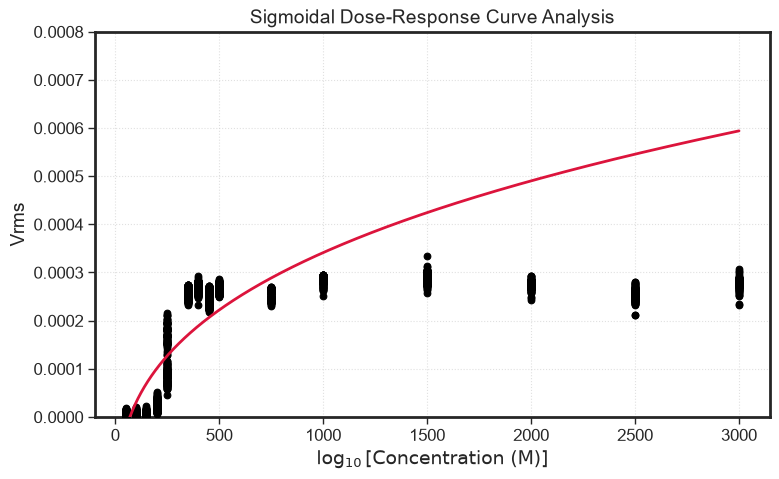

In [35]:
# Extract standard errors from the covariance matrix diagonal
perr = np.sqrt(np.diag(pcov))

bottom, top, log_ec50, hill_slope = popt
ec50_molar = 10**log_ec50

# 5. Calculate Goodness of Fit (R-squared)
# residuals = response - logistic4p(log_conc, *popt)
# ss_res = np.sum(residuals**2)
# ss_tot = np.sum((response - np.mean(response))**2)
# r_squared = 1 - (ss_res / ss_tot)

# Print Summary
print(f"--- Fit Results ---")
print(f"Bottom:     {bottom:.2f} ± {perr[0]:.2f}")
print(f"Top:        {top:.2f} ± {perr[1]:.2f}")
print(f"LogEC50:    {log_ec50:.2f} ± {perr[2]:.2f}")
print(f"EC50:       {ec50_molar:.2e} M ({ec50_molar:.2f} µA)")
print(f"Hill Slope: {hill_slope:.2f} ± {perr[3]:.2f}")
#print(f"R² Score:   {r_squared:.4f}")

# 6. Visualization
x_dense = np.linspace(min(data[:,0]), max(data[:,0]),3000)
y_dense = sigmoid_log10(np.log10(x_dense), *popt)

plt.figure(figsize=(8, 5))
plt.scatter(data[:,0], data[:,1], color='black', label='Data Points', zorder=3)
plt.plot(x_dense, y_dense, color='crimson', linewidth=2, zorder = 4)#, label=f'4PL Fit ($R^2 = {r_squared:.3f}$)')

# Annotate EC50
#plt.axvline(10**log_ec50, color='gray', linestyle='--', alpha=0.7, label=f'$EC_{{50}} = {ec50_molar:.2f}\\ \\mu A$')

plt.xlabel(r'$\log_{10}[\text{Concentration (M)}]$')
plt.ylabel('Vrms')
plt.title('Sigmoidal Dose-Response Curve Analysis')
#plt.legend(frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.ylim((0,0.0008))
plt.tight_layout()
plt.show()

[(0, 2)]
Plotting trace #s 0 to 100


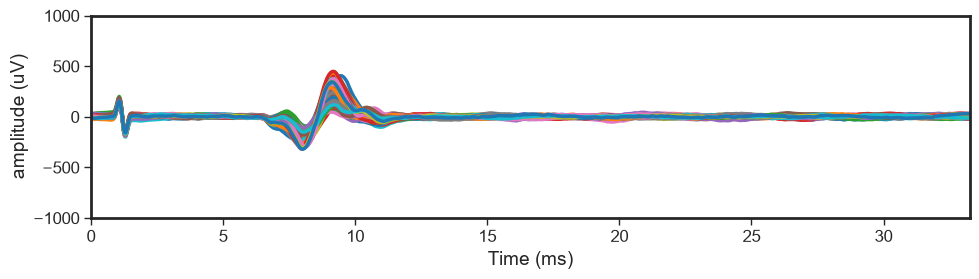

In [38]:
EMGf.plot_binned_traces(channel = 'Wav1 8', parameter = (0,2), bin = (0,100), y_lim = (-1e3,1e3))

In [ ]:
x[0][0]

In [ ]:
m[(0,0)]